# RetailMind AI - Day 7: MobileNetV2 + YOLO (Jupyter-Safe)

This notebook keeps all Day 7 work in **one notebook**, but uses a deliberate **kernel restart between TensorFlow/MobileNetV2 and PyTorch/YOLO**. This is the safest readable approach for the constrained work-laptop environment.

**Important:** Restarting the kernel clears variables from memory, but it does **not** restart the notebook from the beginning and it does **not** delete saved files. After restarting, continue manually from **PART B**. Do not click Run All after the restart.

# PART A - MobileNetV2 Transfer Learning
Run Sections 1-8 first. After Section 8 finishes and the model/metrics are saved, stop and restart the kernel exactly where instructed.

## 1. Imports and project paths

In [1]:
from pathlib import Path
import json
import os
os.environ['CUDA_VISIBLE_DEVICES'] = '-1'
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
import tensorflow as tf
from tensorflow import keras
tf.keras.utils.set_random_seed(42)

current = Path.cwd().resolve()
PROJECT_ROOT = current.parent if current.name == 'notebooks' else current
MODELS_DIR = PROJECT_ROOT / 'models'
MODELS_DIR.mkdir(parents=True, exist_ok=True)
print('Project root:', PROJECT_ROOT)
print('TensorFlow:', tf.__version__)

I0000 00:00:1794422568.033921 1940065 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794422573.625801 1940065 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


Project root: /home/jovyan/work/RetailMind
TensorFlow: 2.21.0


## 2. Load a laptop-safe Fashion-MNIST subset

In [2]:
(x_train_all, y_train_all), (x_test_all, y_test_all) = keras.datasets.fashion_mnist.load_data()
TRAIN_LIMIT = 4000
VAL_SIZE = 800
TEST_LIMIT = 2000
x_train_all, y_train_all = x_train_all[:TRAIN_LIMIT], y_train_all[:TRAIN_LIMIT]
x_test, y_test = x_test_all[:TEST_LIMIT], y_test_all[:TEST_LIMIT]
x_train, y_train = x_train_all[:-VAL_SIZE], y_train_all[:-VAL_SIZE]
x_val, y_val = x_train_all[-VAL_SIZE:], y_train_all[-VAL_SIZE:]
print('Training:', x_train.shape)
print('Validation:', x_val.shape)
print('Test:', x_test.shape)

Training: (3200, 28, 28)
Validation: (800, 28, 28)
Test: (2000, 28, 28)


## 3. Prepare images for MobileNetV2

In [3]:
IMG_SIZE = 64
BATCH_SIZE = 8
def prepare_image(image, label):
    image = tf.cast(image, tf.float32)
    image = tf.expand_dims(image, -1)
    image = tf.image.grayscale_to_rgb(image)
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    image = keras.applications.mobilenet_v2.preprocess_input(image)
    return image, label
def make_dataset(images, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((images, labels))
    if training:
        ds = ds.shuffle(len(images), seed=42)
    return ds.map(prepare_image, num_parallel_calls=1).batch(BATCH_SIZE)
train_ds = make_dataset(x_train, y_train, True)
val_ds = make_dataset(x_val, y_val)
test_ds = make_dataset(x_test, y_test)
print('Image size:', IMG_SIZE, 'Batch size:', BATCH_SIZE)

Image size: 64 Batch size: 8


E0000 00:00:1794422588.422684 1940065 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


## 4. Freeze an ImageNet-pretrained MobileNetV2 backbone

In [4]:
base_model = keras.applications.MobileNetV2(weights='imagenet', include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))
base_model.trainable = False
inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
x = base_model(inputs, training=False)
x = keras.layers.GlobalAveragePooling2D()(x)
x = keras.layers.Dropout(0.30)(x)
outputs = keras.layers.Dense(10, activation='softmax')(x)
transfer_model = keras.Model(inputs, outputs)
transfer_model.compile(optimizer=keras.optimizers.Adam(1e-3), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
transfer_model.summary()

/tmp/ipykernel_1940065/2017018392.py:1: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = keras.applications.MobileNetV2(weights='imagenet', include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 2, 2, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,270,794 (8.66 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 5. Train the new head

In [5]:
head_stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=1, restore_best_weights=True)
head_history = transfer_model.fit(train_ds, validation_data=val_ds, epochs=3, callbacks=[head_stop], verbose=1)
print('Head-training epochs:', len(head_history.history['loss']))

Epoch 1/3


/opt/conda/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


400/400 ━━━━━━━━━━━━━━━━━━━━ 19s 41ms/step - accuracy: 0.6700 - loss: 1.0666 - val_accuracy: 0.7763 - val_loss: 0.6698
Epoch 2/3
400/400 ━━━━━━━━━━━━━━━━━━━━ 15s 38ms/step - accuracy: 0.7987 - loss: 0.5874 - val_accuracy: 0.7925 - val_loss: 0.6270
Epoch 3/3
400/400 ━━━━━━━━━━━━━━━━━━━━ 16s 39ms/step - accuracy: 0.8347 - loss: 0.4714 - val_accuracy: 0.8012 - val_loss: 0.6281
Head-training epochs: 3


## 6. Fine-tune the top MobileNetV2 layers

In [6]:
base_model.trainable = True
for layer in base_model.layers[:-20]:
    layer.trainable = False
for layer in base_model.layers[-20:]:
    if isinstance(layer, keras.layers.BatchNormalization):
        layer.trainable = False
transfer_model.compile(optimizer=keras.optimizers.Adam(1e-5), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
fine_history = transfer_model.fit(train_ds, validation_data=val_ds, epochs=2, verbose=1)
print('Fine-tuning epochs:', len(fine_history.history['loss']))

Epoch 1/2
400/400 ━━━━━━━━━━━━━━━━━━━━ 33s 74ms/step - accuracy: 0.8447 - loss: 0.4351 - val_accuracy: 0.8150 - val_loss: 0.5795
Epoch 2/2
400/400 ━━━━━━━━━━━━━━━━━━━━ 28s 70ms/step - accuracy: 0.8734 - loss: 0.3543 - val_accuracy: 0.8175 - val_loss: 0.5437
Fine-tuning epochs: 2


## 7. Evaluate against Day 6 CNN

In [7]:
test_loss, mobilenet_accuracy = transfer_model.evaluate(test_ds, verbose=0)
day6_accuracy = 0.8854
accuracy_change = mobilenet_accuracy - day6_accuracy
print('Day 6 CNN accuracy:', f'{day6_accuracy:.4f}')
print('MobileNetV2 accuracy:', f'{mobilenet_accuracy:.4f}')
print('Accuracy change:', f'{accuracy_change:+.4f}')
print('Test loss:', f'{test_loss:.4f}')

Day 6 CNN accuracy: 0.8854
MobileNetV2 accuracy: 0.8180
Accuracy change: -0.0674
Test loss: 0.5175


## 8. Save MobileNetV2 model and results BEFORE restarting

In [8]:
classifier_path = MODELS_DIR / 'catalog_transfer_mobilenetv2.keras'
metrics_path = MODELS_DIR / 'day7_mobilenet_metrics.json'
transfer_model.save(classifier_path)
transfer_metrics = {
    'backbone': 'MobileNetV2',
    'day6_accuracy': float(day6_accuracy),
    'transfer_accuracy': float(mobilenet_accuracy),
    'accuracy_change': float(accuracy_change),
    'test_loss': float(test_loss),
    'head_epochs': len(head_history.history['loss']),
    'fine_tune_epochs': len(fine_history.history['loss']),
    'artifact': 'models/catalog_transfer_mobilenetv2.keras'
}
with open(metrics_path, 'w') as f:
    json.dump(transfer_metrics, f, indent=2)
print('Saved:', classifier_path)
print('Saved:', metrics_path)
print('PART A COMPLETE. STOP HERE.')

Saved: /home/jovyan/work/RetailMind/models/catalog_transfer_mobilenetv2.keras
Saved: /home/jovyan/work/RetailMind/models/day7_mobilenet_metrics.json
PART A COMPLETE. STOP HERE.


# ⛔ RESTART THE KERNEL HERE

# PART B - YOLO Object Detection
Start here after the kernel restart.

## 9. Recreate only the paths needed for YOLO

In [1]:
from pathlib import Path
import json
import os
os.environ['CUDA_VISIBLE_DEVICES'] = '-1'
current = Path.cwd().resolve()
PROJECT_ROOT = current.parent if current.name == 'notebooks' else current
MODELS_DIR = PROJECT_ROOT / 'models'
SAMPLE_IMAGE = PROJECT_ROOT / 'data' / 'product_images' / 'sample.jpg'
YOLO_WEIGHTS = PROJECT_ROOT / 'notebooks' / 'yolo11n.pt'
assert SAMPLE_IMAGE.exists(), f'Missing image: {SAMPLE_IMAGE}'
assert (MODELS_DIR / 'day7_mobilenet_metrics.json').exists(), 'Run PART A before PART B.'
print('Sample image:', SAMPLE_IMAGE)
print('MobileNet results found on disk.')

Sample image: /home/jovyan/work/RetailMind/data/product_images/sample.jpg
MobileNet results found on disk.


## 10. Load YOLO and run CPU detection

In [2]:
from ultralytics import YOLO
model_source = str(YOLO_WEIGHTS) if YOLO_WEIGHTS.exists() else 'yolo11n.pt'
detector = YOLO(model_source)
detection_results = detector.predict(
    source=str(SAMPLE_IMAGE),
    device='cpu',
    imgsz=320,
    conf=0.25,
    save=True,
    project=str(MODELS_DIR / 'yolo_predictions'),
    name='day7',
    exist_ok=True,
    verbose=False
)
print('Images processed:', len(detection_results))

Results saved to /home/jovyan/work/RetailMind/models/yolo_predictions/day7
Images processed: 1


## 11. Inspect detected classes, confidence scores, and boxes

In [3]:
detections = []
for result in detection_results:
    for box in result.boxes:
        class_id = int(box.cls[0])
        item = {
            'class': result.names[class_id],
            'confidence': round(float(box.conf[0]), 4),
            'box': [round(float(v), 1) for v in box.xyxy[0]]
        }
        detections.append(item)
print('Bounding boxes detected:', len(detections))
for item in detections:
    print(f"{item['class']} confidence={item['confidence']:.3f} box={item['box']}")

Bounding boxes detected: 1
suitcase confidence=0.532 box=[90.1, 204.3, 164.5, 272.1]


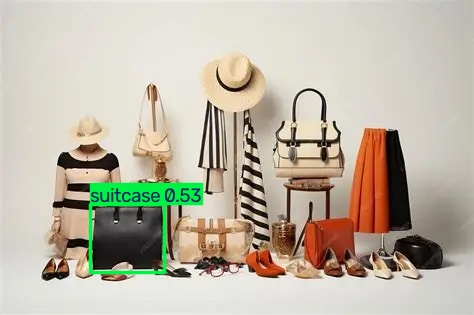

In [7]:
from IPython.display import Image,display
output_image=MODELS_DIR/"yolo_predictions"/"day7"/"sample.jpg"
display(Image(filename=str(output_image)))

## 12. Save YOLO metadata

In [4]:
yolo_summary = {
    'source': 'data/product_images/sample.jpg',
    'images_processed': len(detection_results),
    'bounding_boxes': len(detections),
    'detections': detections,
    'output_folder': 'models/yolo_predictions/day7'
}
with open(MODELS_DIR / 'day7_yolo_results.json', 'w') as f:
    json.dump(yolo_summary, f, indent=2)
print('Saved: models/day7_yolo_results.json')
print('Annotated output: models/yolo_predictions/day7/')

Saved: models/day7_yolo_results.json
Annotated output: models/yolo_predictions/day7/


## 13. Reload MobileNet results and print the final Day 7 summary

In [5]:
with open(MODELS_DIR / 'day7_mobilenet_metrics.json') as f:
    transfer_metrics = json.load(f)
with open(MODELS_DIR / 'day7_yolo_results.json') as f:
    yolo_metrics = json.load(f)
print('DAY 7 - MOBILENETV2 TRANSFER LEARNING & OBJECT DETECTION')
print('-' * 70)
print('Day 6 CNN accuracy:', f"{transfer_metrics['day6_accuracy']:.4f}")
print('MobileNetV2 accuracy:', f"{transfer_metrics['transfer_accuracy']:.4f}")
print('Accuracy change:', f"{transfer_metrics['accuracy_change']:+.4f}")
print('Transfer test loss:', f"{transfer_metrics['test_loss']:.4f}")
print('Classifier:', transfer_metrics['artifact'])
print('YOLO source:', yolo_metrics['source'])
print('Images processed:', yolo_metrics['images_processed'])
print('Bounding boxes detected:', yolo_metrics['bounding_boxes'])
print('Detection output:', yolo_metrics['output_folder'])

DAY 7 - MOBILENETV2 TRANSFER LEARNING & OBJECT DETECTION
----------------------------------------------------------------------
Day 6 CNN accuracy: 0.8854
MobileNetV2 accuracy: 0.8180
Accuracy change: -0.0674
Transfer test loss: 0.5175
Classifier: models/catalog_transfer_mobilenetv2.keras
YOLO source: data/product_images/sample.jpg
Images processed: 1
Bounding boxes detected: 1
Detection output: models/yolo_predictions/day7


## 14. Verify required Day 7 artifacts

In [6]:
required = [
    MODELS_DIR / 'catalog_transfer_mobilenetv2.keras',
    MODELS_DIR / 'day7_mobilenet_metrics.json',
    MODELS_DIR / 'day7_yolo_results.json',
    MODELS_DIR / 'yolo_predictions' / 'day7'
]
for path in required:
    print(('OK' if path.exists() else 'MISSING'), '-', path.relative_to(PROJECT_ROOT))
assert all(path.exists() for path in required), 'A Day 7 artifact is missing.'
print('Day 7 completed successfully.')

OK - models/catalog_transfer_mobilenetv2.keras
OK - models/day7_mobilenet_metrics.json
OK - models/day7_yolo_results.json
OK - models/yolo_predictions/day7
Day 7 completed successfully.


## Requirement coverage

- Pretrained ImageNet MobileNetV2 backbone
- Frozen feature extractor and new classification head
- Low-learning-rate fine-tuning
- Comparison with Day 6 CNN
- Versioned transfer-learning classifier
- Pretrained Ultralytics YOLO detector
- Product image object detection
- Classes, confidence values, and bounding boxes
- Saved annotated detections and JSON metadata
- Everything remains in one Jupyter notebook; the only manual action is one kernel restart between PART A and PART B